# 09 · Discrete noise and probability sets

We fit a structural mechanism `x = clip(g(pa) + U)` to simulated data, read back
the law of the noise `U`, and put a 90% guarantee on the learned probabilities
in three ways: per-entry intervals, L1 balls, and a polytope on the shared
noise law.

- **NBN API:** `nbn.scm.StructuralCausalModel`, `DiscreteAdditiveNoiseMechanism`,
  `noise_parameter_set`; `nbn.uncertainty.interval_set`, `l1_ball_set`,
  `count_table_for`, `interval_set_from_counts`.
- **Runtime:** under 10 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

Ground truth (hidden from the learner):

    health' = clip(health + exercise * (rested - tired) + U, 0, 3),
    U in {-1, 0, +1} with probabilities (0.15, 0.70, 0.15).

In [1]:
import os

import matplotlib.pyplot as plt
import torch

from nbn.scm import DiscreteAdditiveNoiseMechanism, StructuralCausalModel, noise_parameter_set
from nbn.uncertainty import interval_set, l1_ball_set
from nbn.utils.device import resolve_device

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)

BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
                     "font.size": 9})


def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()

device: cpu


## The data

3000 rows from the simulator.  The data stay on the CPU; the model moves them to
its own device.

In [2]:
torch.manual_seed(0)
TRUE_NOISE = torch.tensor([0.15, 0.70, 0.15])


def simulate(n: int, p_tired: float | None = None) -> dict:
    """n rows; a patient is tired w.p. 1/2, or w.p. p_tired when given (used in section 6)."""
    health = torch.randint(0, 4, (n,))
    tired = torch.randint(0, 2, (n,)) if p_tired is None else torch.bernoulli(torch.full((n,), p_tired)).long()
    exercise = torch.randint(0, 2, (n,))
    u = torch.multinomial(TRUE_NOISE, n, replacement=True) - 1
    nxt = (health + exercise * (1 - 2 * tired) + u).clamp(0, 3)
    return {"health": health.float(), "tired": tired.float(), "exercise": exercise.float(),
            "health'": nxt.float()}


data = simulate(3000)

## 1. A structural causal model

`health'` gets an explicit noise law (`DiscreteAdditiveNoiseMechanism`); the
other nodes get plain tables (`auto_mechanisms`).  After `fit`, the mechanism
holds the offsets and their probabilities.

In [3]:
def fit_model(rows: dict) -> StructuralCausalModel:
    model = StructuralCausalModel(
        [("health", "health'"), ("tired", "health'"), ("exercise", "health'")],
        {"health": ("discrete", 4), "tired": ("discrete", 2), "exercise": ("discrete", 2),
         "health'": ("discrete", 4)},
        device=device,
    )
    model.set_mechanism("health'", DiscreteAdditiveNoiseMechanism(max_offset=1))
    model.auto_mechanisms()                # plain tables for the other nodes
    model.fit(rows)
    return model


model = fit_model(data)
mech = model.mechanisms["health'"]
print("offsets          ", mech.noise.offsets.tolist())
print("learned noise law", [round(p, 3) for p in mech.noise.probs.tolist()])
print("true noise law   ", [round(p, 3) for p in TRUE_NOISE.tolist()])

offsets           [-1, 0, 1]
learned noise law [0.143, 0.708, 0.149]
true noise law    [0.15, 0.7, 0.15]


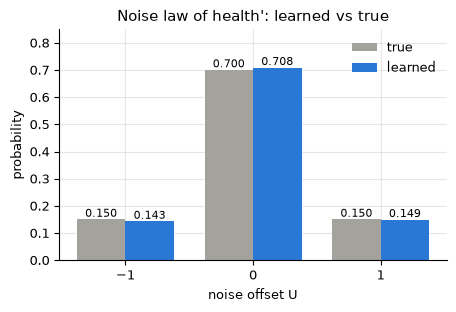

In [4]:
offsets = to_numpy(mech.noise.offsets)
fig, ax = plt.subplots(figsize=(5, 3))
width = 0.38
bars_true = ax.bar(offsets - width / 2, to_numpy(TRUE_NOISE), width, color=GREY, label="true")
bars_fit = ax.bar(offsets + width / 2, to_numpy(mech.noise.probs), width, color=BLUE, label="learned")
for bars in (bars_true, bars_fit):
    ax.bar_label(bars, fmt="%.3f", fontsize=8)
ax.set(xticks=offsets, xlabel="noise offset U", ylabel="probability", ylim=(0, 0.85),
       title="Noise law of health': learned vs true")
ax.legend(frameon=False)
plt.show()

## 2. Interventional queries

The model is still an ordinary NBN, so `query` with `do=` works as before.

In [5]:
print("P(health' | health=1, rested, do(exercise=1)) =",
      [round(p, 3) for p in model.query(["health'"], evidence={"health": 1, "tired": 0},
                                        do={"exercise": 1}).reshape(-1).tolist()])

P(health' | health=1, rested, do(exercise=1)) = [0.0, 0.143, 0.708, 0.149]


## 3. Three probability sets at level 0.90

Each set contains the true table with probability at least 90%, for all
entries at once.

- **Per-entry intervals** (`interval_set`): a min and a max for every probability.
- **L1 balls** (`l1_ball_set`): one ball around each row of the table.
- **Noise polytope** (`noise_parameter_set`): constraints on the shared noise
  law.  Every row of the table is a function of that one law, so all rows pool
  their data and the bounds are much tighter.

In [6]:
box = interval_set(model, data, "health'", delta=0.1)          # min / max per probability
ball = l1_ball_set(model, data, "health'", delta=0.1)          # one L1 ball per row
polytope = noise_parameter_set(model, data, ["health'"], delta=0.1)   # on the shared law

print("mean width of the bounds (smaller = tighter):")
print(f"  per-entry intervals {box.width().mean():.3f}")
print(f"  L1 balls            {ball.width().mean():.3f}")
noise_box = polytope.table_set("health'")
print(f"  noise polytope      {noise_box.width().mean():.3f}")
print("true noise law inside the polytope:", polytope.contains(TRUE_NOISE.double()))

mean width of the bounds (smaller = tighter):
  per-entry intervals 0.131
  L1 balls            0.221
  noise polytope      0.030
true noise law inside the polytope: True


## 4. The bounds of one row

Row `health=1, rested, exercise=1` (rows are in C order over the parents
`health, tired, exercise`).

In [7]:
row = (1 * 2 + 0) * 2 + 1
lower, upper = noise_box.bounds()
print("P(health' | health=1, rested, exercise=1):")
for k in range(4):
    print(f"  health'={k}: [{lower[row, k]:.3f}, {upper[row, k]:.3f}]")

P(health' | health=1, rested, exercise=1):
  health'=0: [0.000, 0.000]
  health'=1: [0.120, 0.167]
  health'=2: [0.675, 0.746]
  health'=3: [0.126, 0.175]


The plot shows the bounds of all three sets for this row, with the true
probabilities.  We build the true table from the simulator and check that it
matches the learned one.

largest |learned - true| over the whole table: 0.008


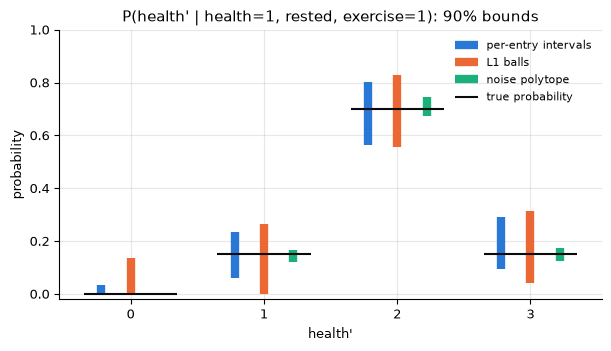

In [8]:
def true_table() -> torch.Tensor:
    """P(health' | health, tired, exercise) of the simulator, rows in C order."""
    health, tired, exercise = torch.meshgrid(torch.arange(4), torch.arange(2), torch.arange(2),
                                             indexing="ij")
    location = (health + exercise * (1 - 2 * tired)).reshape(-1)
    table = torch.zeros(16, 4)
    for offset, p in zip((-1, 0, 1), TRUE_NOISE.tolist()):
        table[torch.arange(16), (location + offset).clamp(0, 3)] += p
    return table


TRUE_TABLE = true_table()
print("largest |learned - true| over the whole table:",
      round(float((mech.table().detach().cpu() - TRUE_TABLE).abs().max()), 3))

sets = {"per-entry intervals": box, "L1 balls": ball, "noise polytope": noise_box}
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, ((name, prob_set), color) in enumerate(zip(sets.items(), (BLUE, ORANGE, AQUA))):
    lo, hi = (to_numpy(b[row]) for b in prob_set.bounds())
    x = [k + (i - 1) * 0.22 for k in range(4)]
    ax.vlines(x, lo, hi, color=color, lw=6, label=name)
ax.hlines(to_numpy(TRUE_TABLE[row]), [k - 0.35 for k in range(4)], [k + 0.35 for k in range(4)],
          color=INK, lw=1.5, label="true probability")
ax.set(xticks=range(4), xlabel="health'", ylabel="probability", ylim=(-0.02, 1),
       title="P(health' | health=1, rested, exercise=1): 90% bounds")
ax.legend(frameon=False, fontsize=8)
plt.show()

## 5. Do the sets keep their promise?

The 90% level is a statement about repeated sampling: over many datasets, each
set should contain the truth at least 90% of the time.  On simulated data we
can check it.  We draw 100 new datasets of the same size, rebuild the three
sets, and count how often each contains the truth (the true table for the
intervals and the balls, the true noise law for the polytope).

In [9]:
n_repeats = 100
names = list(sets)
covered = dict.fromkeys(names, 0)
widths = {name: [] for name in names}
for _ in range(n_repeats):
    rows = simulate(3000)
    m = fit_model(rows)
    b = interval_set(m, rows, "health'", delta=0.1)
    l1 = l1_ball_set(m, rows, "health'", delta=0.1)
    p = noise_parameter_set(m, rows, ["health'"], delta=0.1)
    for name, ok, w in ((names[0], b.contains(TRUE_TABLE), b.width()),
                        (names[1], l1.contains(TRUE_TABLE), l1.width()),
                        (names[2], p.contains(TRUE_NOISE), p.table_set("health'").width())):
        covered[name] += int(ok)
        widths[name].append(float(w.mean()))

print(f"coverage over {n_repeats} datasets (target >= 0.90):")
for name in names:
    print(f"  {name:20s} {covered[name] / n_repeats:.2f}   mean width {sum(widths[name]) / n_repeats:.3f}")

coverage over 100 datasets (target >= 0.90):
  per-entry intervals  0.98   mean width 0.133
  L1 balls             1.00   mean width 0.221
  noise polytope       1.00   mean width 0.030


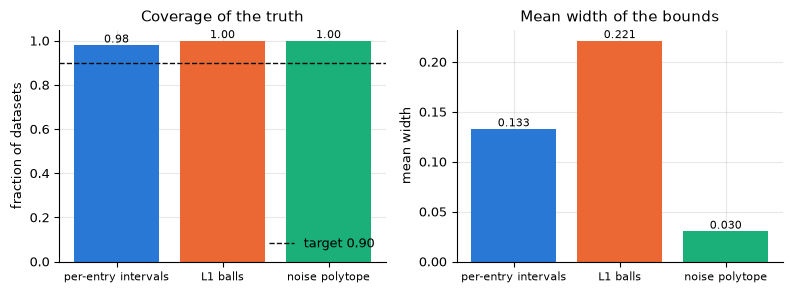

In [10]:
fig, (ax_cov, ax_w) = plt.subplots(1, 2, figsize=(8, 3))
colors = [BLUE, ORANGE, AQUA]
ax_cov.bar_label(ax_cov.bar(names, [covered[n] / n_repeats for n in names], color=colors),
                 fmt="%.2f", fontsize=8)
ax_cov.axhline(0.9, color=INK, ls="--", lw=1, label="target 0.90")
ax_cov.set(ylim=(0, 1.05), ylabel="fraction of datasets", title="Coverage of the truth")
ax_cov.legend(frameon=False, loc="lower right")
ax_w.bar_label(ax_w.bar(names, [sum(widths[n]) / n_repeats for n in names], color=colors),
               fmt="%.3f", fontsize=8)
ax_w.set(ylabel="mean width", title="Mean width of the bounds")
for ax in (ax_cov, ax_w):
    ax.tick_params(axis="x", labelsize=8)
fig.tight_layout()
plt.show()

All three sets cover the truth at least as often as promised.  The polytope
does so with bounds several times narrower, because it uses the structure
(one noise law shared by every row).  That structure is an assumption: check it
with `noise_sharing_test` (notebook 10).

## 6. Sets from a count table: comparing candidate parent sets

The builders above only need the **counts** of `health'` per parent value.
`count_table_for` counts a node against *any* tuple of parents, and each builder
has a `*_from_counts` twin, so we can build a set for a candidate parent set
without a model for it.  Two candidates for `health'`:

- `(health, tired, exercise)`: the true parents;
- `(health, exercise)`: misses `tired`.

Two sets must hold at once, so each gets `delta / 2` (union bound).

In [11]:
from nbn.uncertainty import count_table, count_table_for, interval_set_from_counts

candidates = [("health", "tired", "exercise"), ("health", "exercise")]
for parents in candidates:
    counts, cards = count_table_for(model.variables, data, "health'", parents)
    s = interval_set_from_counts(counts, delta=0.1 / len(candidates))
    print(f"{str(parents):32s} rows {counts.shape[0]:2d}   mean width {s.width().mean():.3f}")

# The model-based builder is the same computation on the model's own parents.
same = interval_set(model, data, "health'", delta=0.1)
again = interval_set_from_counts(count_table(model, data, "health'")[0], delta=0.1)
print("interval_set == interval_set_from_counts(count_table(...)):",
      bool(torch.equal(same.lower, again.lower) and torch.equal(same.upper, again.upper)))

('health', 'tired', 'exercise')  rows 16   mean width 0.138
('health', 'exercise')           rows  8   mean width 0.119
interval_set == interval_set_from_counts(count_table(...)): True


The smaller candidate has fewer rows and more data per row, so its bounds are
narrower.  But it is not the true conditional: it averages over `tired` with
the weights of *this* dataset.  A logger that sees tired patients more often
gives a different table for the same candidate, while the true parents give the
same one.  We count both candidates on data where 90% of the rows are tired.

In [12]:
other = simulate(3000, p_tired=0.9)
row_small = 1 * 2 + 1                      # health=1, exercise=1 in C order over (health, exercise)
print("P(health' | health=1, exercise=1) from the candidate without tired:")
for name, rows in (("first dataset (tired 50%)", data), ("second dataset (tired 90%)", other)):
    counts, _ = count_table_for(model.variables, rows, "health'", ("health", "exercise"))
    print(f"  {name:28s}", [round(p, 2) for p in (counts[row_small] / counts[row_small].sum()).tolist()])
print("true rows: rested", [round(p, 2) for p in TRUE_TABLE[(1 * 2 + 0) * 2 + 1].tolist()],
      " tired", [round(p, 2) for p in TRUE_TABLE[(1 * 2 + 1) * 2 + 1].tolist()])

P(health' | health=1, exercise=1) from the candidate without tired:
  first dataset (tired 50%)    [0.39, 0.14, 0.38, 0.1]
  second dataset (tired 90%)   [0.79, 0.14, 0.05, 0.02]
true rows: rested [0.0, 0.15, 0.7, 0.15]  tired [0.85, 0.15, 0.0, 0.0]


With the true parents the table would not move (it is `P(health' | parents)`,
whatever the logger).  A candidate that misses a parent depends on how the
data were collected.  `nbn.structure.HypothesisSet` builds on these functions
to handle many candidate parent sets at once (notebook 14).